In [1]:
import sys
from pathlib import Path

import tensorflow as tf
from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils.scores import CategoricalScore
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
from src.image_pipeline import create_dataset

I0000 00:00:1795685410.958912   11047 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795685411.049291   11047 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795685412.680178   11047 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
IMG_SIZE=(224,224)
BATCH_SIZE=32
SEED = 42
tf.keras.utils.set_random_seed(SEED)

label_encoder = joblib.load("../dataset/label_encoder.joblib")
class_names = label_encoder.classes_

CHOSEN_PATH = Path("../models/chosen.keras")

In [10]:
val_df = pd.read_csv("../dataset/val_processed.csv")

val = create_dataset(
    val_df,
    training=False,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

print(f"Validation: {len(val_df)}")

images, labels = next(iter(val))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)

Validation: 1602
Image batch: (32, 224, 224, 3)
Label batch: (32, 7)


## 1. Wczytanie wytrenowanego modelu

In [4]:
model = tf.keras.models.load_model(CHOSEN_PATH)

model.summary(expand_nested=True)

Model: "CW10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 7)              │     4,058,538 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ input_layer_1 (InputLayer) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ efficientnetb0             │ (None, 7, 7, 1280)     │     4,049,571 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ input_layer             │ (None, 224, 224, 3)    │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ rescaling (Rescaling)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ normalization           │ (None, 224, 224, 3)    │             7 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ rescaling_1 (Rescaling) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ stem_conv_pad           │ (None, 225, 225, 3)    │             0 │
│ (ZeroPadding2D)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ stem_conv (Conv2D)      │ (None, 112, 112, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ stem_bn                 │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ stem_activation         │ (None, 112, 112, 32)   │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ block1a_dwconv          │ (None, 112, 112, 32)   │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ block1a_bn              │ (None, 112, 112, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ block1a_activation      │ (None, 112, 112, 32)   │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ block1a_se_squeeze      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ block1a_se_reshape      │ (None, 1, 1, 32)       │             0 │
│ (Reshape)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ block1a_se_reduce       │ (None, 1, 1, 8)        │           264 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│       └ block1a_se_expand       │ (None, 1, 1, 32)       │           28

 Total params: 10,336,242 (39.43 MB)

 Trainable params: 3,138,851 (11.97 MB)

 Non-trainable params: 919,687 (3.51 MB)

 Optimizer params: 6,277,704 (23.95 MB)

In [5]:
for layer in model.layers:
    print(layer.name, type(layer).__name__)

input_layer InputLayer
functional Functional


In [8]:
backbone = model.get_layer("functional").get_layer("efficientnetb0")

for layer in backbone.layers[-15:]:
    print(layer.name, layer.output.shape)

block7a_expand_bn (None, 7, 7, 1152)
block7a_expand_activation (None, 7, 7, 1152)
block7a_dwconv (None, 7, 7, 1152)
block7a_bn (None, 7, 7, 1152)
block7a_activation (None, 7, 7, 1152)
block7a_se_squeeze (None, 1152)
block7a_se_reshape (None, 1, 1, 1152)
block7a_se_reduce (None, 1, 1, 48)
block7a_se_expand (None, 1, 1, 1152)
block7a_se_excite (None, 7, 7, 1152)
block7a_project_conv (None, 7, 7, 320)
block7a_project_bn (None, 7, 7, 320)
top_conv (None, 7, 7, 1280)
top_bn (None, 7, 7, 1280)
top_activation (None, 7, 7, 1280)


## 2. Implementacja Grad-CAM

In [9]:
gradcam = Gradcam(
    model,
    model_modifier=ReplaceToLinear(),
    clone=True
)

In [15]:
samp_img, samp_label = images[0], labels[0]

samp_img = np.expand_dims(samp_img, axis=0)
prediction = model(samp_img)[0]

pred_index = np.argmax(prediction)

score = CategoricalScore([pred_index])

cam = gradcam(
    score,
    samp_img,
    penultimate_layer=backbone.layers[-1],
    seek_penultimate_conv_layer=False
)[0]

# Nałożenie mapy na obraz
heatmap = cm.jet(cam)[..., :3]

display_image = np.clip(
    image / 255.0,
    0,
    1
)

overlay = (
    0.6 * display_image +
    0.4 * heatmap
)

plt.imshow(np.clip(overlay, 0, 1))


plt.axis("off")

plt.suptitle(
    f"Grad-CAM dla klasy: {class_names[pred_index]}",
    fontsize=14
)

plt.tight_layout()
plt.show()

ValueError: The name "input_layer" is used 2 times in the model. All operation names should be unique.

In [14]:
def compare_gradcams(
    image,
    class_index,
    gradcams,
    models,
    class_names,
    penultimate_layer=-1
):
    image_batch = np.expand_dims(image, axis=0)

    fig, axes = plt.subplots(
        1,
        len(gradcams) + 1,
        figsize=(20, 4)
    )

    axes[0].imshow(image.astype("uint8"))
    axes[0].set_title("Oryginał")
    axes[0].axis("off")

    score = CategoricalScore([class_index])

    for ax, (name, gradcam) in zip(axes[1:], gradcams.items()):
        # Predykcja modelu
        prediction = models[name].predict(
            image_batch,
            verbose=0
        )[0]

        pred_index = np.argmax(prediction)

        # Grad-CAM dla wybranej klasy
        cam = gradcam(
            score,
            image_batch,
            penultimate_layer=penultimate_layer
        )[0]

        # Nałożenie mapy na obraz
        heatmap = cm.jet(cam)[..., :3]

        display_image = np.clip(
            image / 255.0,
            0,
            1
        )

        overlay = (
            0.6 * display_image +
            0.4 * heatmap
        )

        ax.imshow(np.clip(overlay, 0, 1))

        ax.set_title(
            f"{name}\n"
            f"Pred: {class_names[pred_index]} "
            f"({prediction[pred_index]:.2f})"
        )

        ax.axis("off")

    plt.suptitle(
        f"Grad-CAM dla klasy: {class_names[class_index]}\n model: {name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

In [18]:
img, label = next(train.as_numpy_iterator())

ValueError: No such layer: efficientnetb0. Existing layers are: ['input_layer', 'augmentation_AUG1', 'functional'].

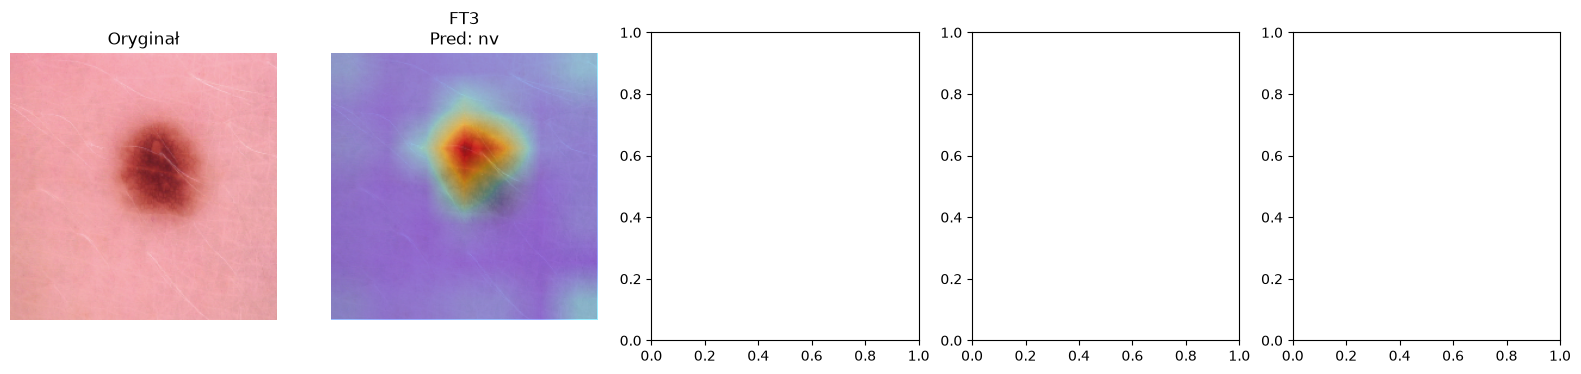

In [26]:
compare_gradcams(
    image=img[0],
    class_index=np.argmax(label[0]),
    models=models,
    class_names=class_names
)

In [21]:
for name, model in models.items():
    print(f"\n{name}")

    for layer in model.layers:
        print(layer.name, type(layer).__name__)


FT3
input_layer_1 InputLayer
efficientnetb0 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense

AUG_FT3
input_layer InputLayer
augmentation_AUG1 Sequential
functional Functional

CW_FT3
input_layer InputLayer
functional Functional

CW_AUG_FT3
input_layer InputLayer
augmentation_AUG1 Sequential
functional Functional


In [22]:
models["FT3"].summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,336,242 (39.43 MB)

 Trainable params: 3,138,851 (11.97 MB)

 Non-trainable params: 919,687 (3.51 MB)

 Optimizer params: 6,277,704 (23.95 MB)

In [23]:
def generate_gradcam(model, image, class_index):
    backbone = model.get_layer("efficientnetb0")

    # Wejście modelu
    image_batch = tf.convert_to_tensor(
        np.expand_dims(image, axis=0),
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:
        # Wyjście backbone
        feature_maps = backbone(image_batch, training=False)
        tape.watch(feature_maps)

        # Przejście przez głowicę
        x = feature_maps

        for layer in model.layers:
            if layer.name in ["global_average_pooling2d", "dropout", "dense"]:
                x = layer(x, training=False)

        # Wynik wybranej klasy
        class_score = x[:, class_index]

    # Gradient wyniku klasy względem map cech
    grads = tape.gradient(class_score, feature_maps)

    # Średnia gradientów po wymiarach przestrzennych
    weights = tf.reduce_mean(grads, axis=(1, 2))

    # Ważona suma map cech
    cam = tf.reduce_sum(
        feature_maps * weights[:, None, None, :],
        axis=-1
    )

    # ReLU
    cam = tf.nn.relu(cam)

    # Normalizacja
    cam = cam / (tf.reduce_max(cam) + 1e-8)

    return cam[0].numpy()

In [24]:
import matplotlib.pyplot as plt

def compare_gradcams(image, class_index, models, class_names):

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))

    # Oryginał
    axes[0].imshow(image.astype("uint8"))
    axes[0].set_title("Oryginał")
    axes[0].axis("off")

    for ax, (name, model) in zip(axes[1:], models.items()):

        cam = generate_gradcam(
            model,
            image,
            class_index
        )

        # Predykcja
        prediction = model.predict(
            np.expand_dims(image, axis=0),
            verbose=0
        )[0]

        pred_index = np.argmax(prediction)

        # Obraz
        ax.imshow(image.astype("uint8"))

        # Heatmap
        ax.imshow(
            cam,
            cmap="jet",
            alpha=0.4,
            interpolation="bilinear",
            extent=(0, image.shape[1], image.shape[0], 0),
            vmin=0,
            vmax=1
        )

        ax.set_title(
            f"{name}\n"
            f"Pred: {class_names[pred_index]}"
        )

        ax.axis("off")

    plt.suptitle(
        f"Grad-CAM dla klasy: {class_names[class_index]}"
    )

    plt.tight_layout()
    plt.show()